# NOVA IMS - Data Mining I (2026/2027)
## Group Project: Student Segmentation
### *"What factors explain different groups of Portuguese students?"*
**A clustering-based exploration of student performance, engagement, and support needs**

---

### Group Information
| Member Name | Student Number |
| :--- | :--- |
| Student 1 | 2026XXXX |
| Student 2 | 2026XXXX |
| Student 3 | 2026XXXX |
| Student 4 | 2026XXXX |

---

## Table of Contents <a id="toc"></a>
* [Chapter 1: Project Overview & Objectives](#ch1)
  * [1.1 Educational Problem & Context](#ch1_1)
  * [1.2 Core Objectives](#ch1_2)
* [Chapter 2: Environment Setup & Data Ingestion](#ch2)
* [Chapter 3: Exploratory Data Analysis](#ch3)
  * [3.1 Data Overview](#ch3_1)
  * [3.2 Q1 – Who are the students?](#ch3_2)
  * [3.3 Q2 – How do students perform academically?](#ch3_3)
  * [3.4 Q3 – How do the two schools differ?](#ch3_4)
  * [3.5 Q4 – What do engagement and lifestyle look like?](#ch3_5)
  * [3.6 Q5 – What support and family background do students have?](#ch3_6)
  * [3.7 Correlation Analysis](#ch3_7)
  * [3.8 EDA Summary & Implications for Preprocessing](#ch3_8)
* [Chapter 4: Data Preprocessing – Inconsistencies & Missing Values](#ch4)
  * [4.1 Working Copy, Variable Types & Duplicates](#ch4_1)
  * [4.2 Inconsistencies](#ch4_2)
    * [4.2.1 Family Size: famsize](#ch4_2_1)
    * [4.2.2 Zero Travel Times: traveltime](#ch4_2_2)
    * [4.2.3 Grade Recording Error: G1](#ch4_2_3)
    * [4.2.4 Final Grade of 0: G3](#ch4_2_4)
  * [4.3 Missing Values](#ch4_3)
    * [4.3.1 Structural Zeros: failures & absences](#ch4_3_1)
    * [4.3.2 School: school (1 missing value)](#ch4_3_2)
    * [4.3.3 Sex & Address: sex (10) and address (17)](#ch4_3_3)
    * [4.3.4 Family & Context Variables: Pstatus, Mjob, Fjob, reason, guardian](#ch4_3_4)
    * [4.3.5 Parental Education: Medu (33) & Fedu (26)](#ch4_3_5)
    * [4.3.6 Travel Time: traveltime (11 missing values)](#ch4_3_6)
    * [4.3.7 Study Time: studytime (14 missing values)](#ch4_3_7)
    * [4.3.8 Binary Variables: schoolsup to romantic](#ch4_3_8)
    * [4.3.9 Ordinal Variables: famrel to health](#ch4_3_9)
  * [4.4 Summary of Data Cleaning](#ch4_4)


# Chapter 1: Project Overview & Objectives <a id="ch1"></a>
[Back to Table of Contents](#toc)

### 1.1 Educational Problem & Context <a id="ch1_1"></a>
Educational institutions face the challenge of identifying students who need timely academic, psychological, or social support. Rather than viewing students monolithically or relying solely on GPA, unsupervised learning allows schools to detect multi-dimensional behavioral, engagement, and background patterns.

### 1.2 Core Objectives <a id="ch1_2"></a>
1. **Understand & Prepare:** Clean, audit, and engineer relevant features from Portuguese secondary school data.
2. **Segment:** Discover stable, cohesive, and well-separated student profiles using clustering techniques.
3. **Interpret & Action:** Provide actionable, ethically sound intervention strategies tailored to each identified group.
4. **Knowledge in Action:** Deploy a practical decision tool for school guidance coordinators.

# Chapter 2: Environment Setup & Data Ingestion <a id="ch2"></a>
[Back to Table of Contents](#toc)

Following the methodology from **Practical 1 (Data Understanding & Visualization)**, we initialize our environment, import the required analytical libraries, and load the dataset using a relative file path.

In [10]:
# 1. Core Data Science & Scientific Libraries
import numpy as np
import pandas as pd
from IPython.display import display

# 2. Data Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Machine Learning & Preprocessing (scikit-learn & scipy)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score,davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage

# 4. Global Settings & Reproducibility
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 2)
sns.set_theme(style="whitegrid", context="notebook")
SEED = 42

print(f"Libraries loaded successfully | pandas version: {pd.__version__} | seaborn version: {sns.__version__}")

Libraries loaded successfully | pandas version: 3.1.1 | seaborn version: 0.13.2


In [11]:
# Ingest the dataset using a relative path as required by submission guidelines
df = pd.read_csv(
    '../data/raw/student_data.csv',
    keep_default_na=False,
    na_values=['']
, index_col=0)  # first column is a leftover row index

# Verify dimensions
print(f"Number of Rows (Students):    {data.shape[0]}")
print(f"Number of Columns (Features): {data.shape[1]}")

Number of Rows (Students):    649
Number of Columns (Features): 33


In [12]:
# Preview the first 5 records of the dataset
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,7.0,A,Higher Education,Higher Education,at_home,teacher,course,mother,17.0,222.0,NaN,yes,no,no,no,yes,NaN,no,no,4.0,3.0,4.0,1.0,1.0,3.0,4.0,0,11,11
1,GP,F,17,U,4.0,T,Primary Education,Primary Education,at_home,other,course,father,6.0,182.0,NaN,no,yes,no,no,no,yes,yes,no,5.0,3.0,3.0,1.0,1.0,3.0,2.0,9,11,11
2,GP,F,15,U,1.0,T,Primary Education,Primary Education,at_home,other,other,mother,NaN,282.0,NaN,NaN,no,no,no,yes,yes,yes,no,4.0,3.0,2.0,2.0,NaN,3.0,6.0,12,13,12
3,GP,F,15,U,4.0,T,Higher Education,Middle School Education,health,services,home,mother,9.0,350.0,NaN,no,yes,no,yes,yes,yes,yes,yes,3.0,2.0,2.0,1.0,1.0,5.0,NaN,14,14,14
4,GP,F,16,U,9.0,T,Secondary Education,Secondary Education,other,other,home,father,6.0,224.0,NaN,no,yes,no,no,yes,yes,no,no,4.0,3.0,2.0,1.0,2.0,5.0,NaN,11,13,13


# Chapter 3: Exploratory Data Analysis <a id="ch3"></a>
[Back to Table of Contents](#toc)

Before preprocessing, we explore the raw data to understand the student population and to spot patterns and inconsistencies that will inform our later decisions. The analysis is organised around five educational questions:

1. [Data Overview](#ch3_1)
2. [Q1 – Who are the students?](#ch3_2)
3. [Q2 – How do students perform academically?](#ch3_3)
4. [Q3 – How do the two schools differ?](#ch3_4)
5. [Q4 – What do engagement and lifestyle look like?](#ch3_5)
6. [Q5 – What support and family background do students have?](#ch3_6)
7. [Correlation Analysis](#ch3_7)
8. [EDA Summary & Implications for Preprocessing](#ch3_8)

## 3.1 Data Overview <a id="ch3_1"></a>

**Step 1** – Check the data types and the number of non-null values for each variable.

In [13]:
# Step 1
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   school      648 non-null    str    
 1   sex         639 non-null    str    
 2   age         649 non-null    int64  
 3   address     632 non-null    str    
 4   famsize     646 non-null    float64
 5   Pstatus     621 non-null    str    
 6   Medu        622 non-null    str    
 7   Fedu        630 non-null    str    
 8   Mjob        643 non-null    str    
 9   Fjob        631 non-null    str    
 10  reason      642 non-null    str    
 11  guardian    641 non-null    str    
 12  traveltime  638 non-null    float64
 13  studytime   635 non-null    float64
 14  failures    98 non-null     float64
 15  schoolsup   619 non-null    str    
 16  famsup      642 non-null    str    
 17  paid        618 non-null    str    
 18  activities  618 non-null    str    
 19  nursery     629 non-null    str    
 20 

> **Observation:** The dataset has 33 variables: 15 numerical (11 float, 4 int) and 18 categorical. All 18 categorical variables and 11 of the numerical ones have missing values. The ordinal variables (`famrel` to `health`), `failures` and `absences` are stored as float only because they contain NaN.

**Step 2** – Obtain the descriptive statistics for the numerical variables.

In [14]:
# Step 2
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
famsize,646.0,4.98,2.82,0.0,3.0,5.0,7.0,9.0
traveltime,638.0,18.21,19.95,0.0,6.0,13.0,25.0,144.0
studytime,635.0,242.21,235.97,0.0,99.5,186.0,282.5,1465.0
failures,98.0,1.43,0.72,1.0,1.0,1.0,2.0,3.0
famrel,625.0,3.92,0.96,1.0,4.0,4.0,5.0,5.0
freetime,629.0,3.19,1.05,1.0,3.0,3.0,4.0,5.0
goout,618.0,3.19,1.18,1.0,2.0,3.0,4.0,5.0
Dalc,625.0,1.51,0.93,1.0,1.0,1.0,2.0,5.0
Walc,622.0,2.28,1.29,1.0,1.0,2.0,3.0,5.0


> **Observation:** Grades stay within the valid 0–20 range, but G1, G2 and G3 all reach 0. `famsize` has a minimum of 0, which is impossible. `traveltime` goes from 0 to 144 minutes and `studytime` from 0 to 1465 min/week (about 24 hours), with the mean (242) well above the median (186), so the distribution is right-skewed. `failures` and `absences` have a minimum of 1 and only 98 and 389 recorded values, which suggests that 0 was never recorded (see Chapter 4). Ages range from 15 to 22.

**Step 3** – Obtain the descriptive statistics for the categorical variables.

In [15]:
# Step 3
# exclude="number" works for both object and the new pandas 3 'str' dtype
df.describe(exclude="number").T

,count,unique,top,freq
school,648,2,GP,422
sex,639,2,F,377
address,632,2,U,443
Pstatus,621,2,T,544
Medu,622,5,Middle School Education,179
Fedu,630,5,Middle School Education,203
Mjob,643,5,other,254
Fjob,631,5,other,358
reason,642,4,course,279
guardian,641,3,mother,450


> **Observation:** Several binary variables are dominated by one level: `paid` is 94% "no" (582/618), `schoolsup` is 89% "no", `higher` is 89% "yes" and `nursery` is 80% "yes". `Medu` and `Fedu` only show 4 levels: the level "None" listed in the project brief never appears. For `Mjob` and `Fjob` the most frequent level is "other".

## 3.2 Q1 – Who are the students? <a id="ch3_2"></a>

**Step 4** – Check how students are distributed between the two schools.

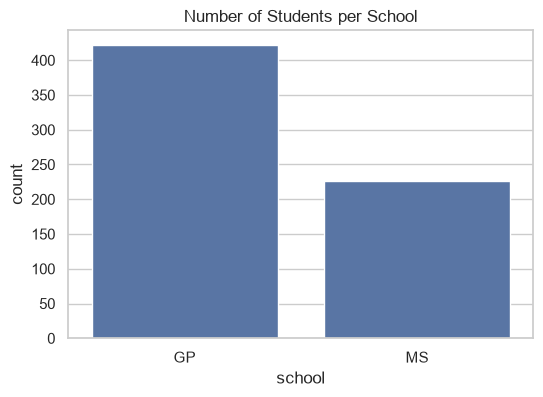

In [16]:
# Step 4
plt.figure(figsize=(6, 4))
sns.countplot(x="school", data=df)
plt.title("Number of Students per School")
plt.show()

**Step 5** – Check the age distribution of students.

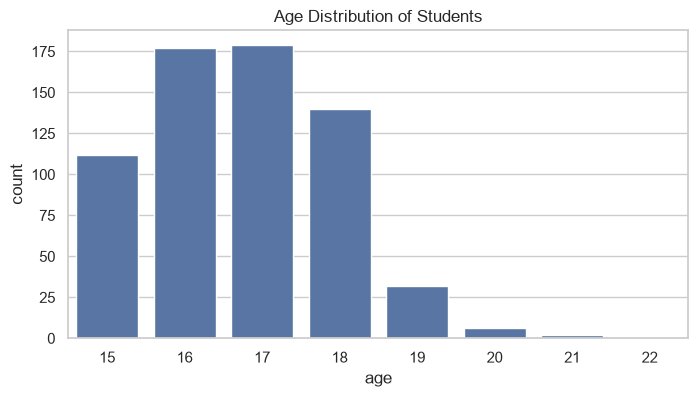

In [17]:
# Step 5
plt.figure(figsize=(8, 4))
sns.countplot(x="age", data=df)
plt.title("Age Distribution of Students")
plt.show()

> **Observation:** Most students (94%) are between 15 and 18. The 41 students aged 19–22 are not errors: 59% of them have at least one past failure, against 15% in the whole dataset, so being older than expected mostly reflects repeating a year.

**Step 6** – Check the distribution of sex and address.

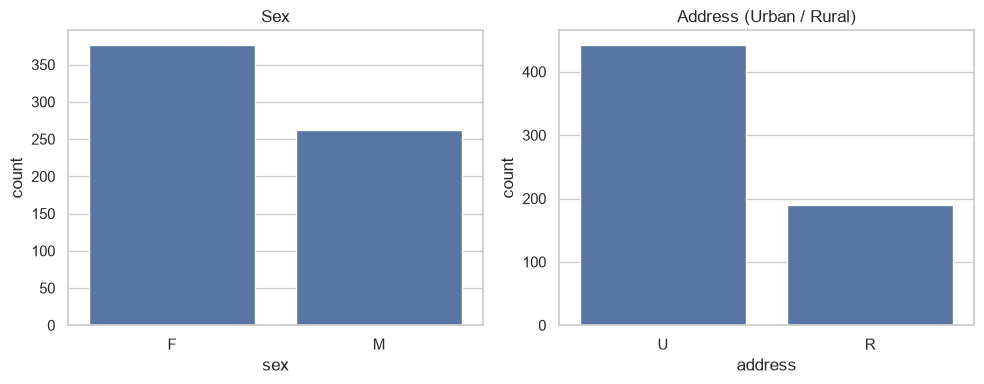

In [18]:
# Step 6
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="sex", data=df, ax=axes[0])
axes[0].set_title("Sex")
sns.countplot(x="address", data=df, ax=axes[1])
axes[1].set_title("Address (Urban / Rural)")
plt.tight_layout()
plt.show()

**Step 7** – Cross-tabulate school and address to see where each school's students live.

In [19]:
# Step 7
# normalize="index" gives the proportion of urban/rural students within each school
pd.crosstab(df["school"], df["address"], normalize="index").round(2)

address,R,U
school,,
GP,0.18,0.82
MS,0.53,0.47


> **Observation:** GP has 65% of the students and is mostly urban (82%), while MS has 35% and over half of its students are rural (53%). School and address are therefore strongly linked, and this should be kept in mind when comparing the schools.

## 3.3 Q2 – How do students perform academically? <a id="ch3_3"></a>

**Step 8** – Plot the distribution of the final grade `G3`.

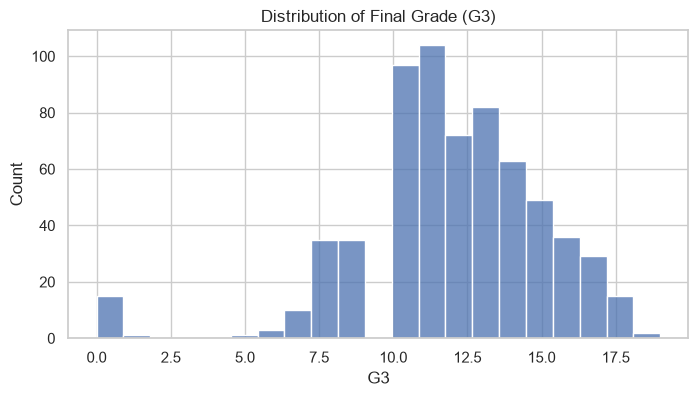

In [20]:
# Step 8
plt.figure(figsize=(8, 4))
sns.histplot(x="G3", data=df, bins=21)
plt.title("Distribution of Final Grade (G3)")
plt.show()

> **Observation:** G3 has a mean of 11.9, a median of 12 and a standard deviation of 3.2. The distribution is roughly bell-shaped around 11–13, with a separate group of students at 0. 15.4% of students are below 10, the passing grade in Portugal.

**Step 9** – Compare the three grading periods side by side.

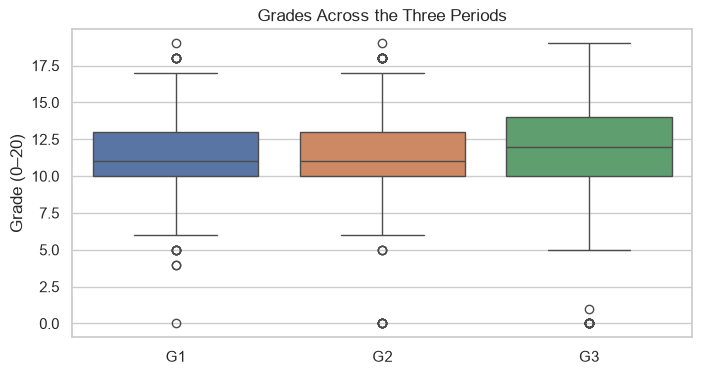

In [21]:
# Step 9
plt.figure(figsize=(8, 4))
sns.boxplot(data=df[["G1", "G2", "G3"]])
plt.title("Grades Across the Three Periods")
plt.ylabel("Grade (0–20)")
plt.show()

**Step 10** – Count how many students have a grade of 0 in each period.

In [22]:
# Step 10
(df[["G1", "G2", "G3"]] == 0).sum()

G1     1
G2     7
G3    15
dtype: int64

**Step 11** – Inspect the students with a final grade of 0.

In [23]:
# Step 11
df[df["G3"] == 0][["G1", "G2", "G3", "failures", "absences", "higher"]]

,G1,G2,G3,failures,absences,higher
163,11,9,0,2.0,NaN,no
440,7,0,0,NaN,NaN,yes
519,8,7,0,NaN,NaN,yes
563,7,0,0,1.0,NaN,yes
567,4,0,0,1.0,NaN,no
583,8,6,0,1.0,NaN,no
586,8,8,0,NaN,NaN,yes
597,9,0,0,1.0,NaN,yes
603,5,0,0,NaN,NaN,NaN
605,5,0,0,1.0,NaN,no


> **Observation:** None of the 15 students with G3 = 0 had 0 in G1 (their G1 is between 4 and 11), and 8 of them still had a positive G2. This looks like students who dropped out or missed the final exam rather than students who scored 0. All 15 also have `absences` missing, so for this group a missing value probably does not mean perfect attendance. Separately, one student has G1 = 0 but G2 = G3 = 11, which looks like a recording error.

**Step 12** – Check the distribution of past failures (missing values included).

In [24]:
# Step 12
df["failures"].value_counts(dropna=False).sort_index()

failures
1.0     69
2.0     16
3.0     13
NaN    551
Name: count, dtype: int64

**Step 13** – Compare the final grade across the number of past failures.

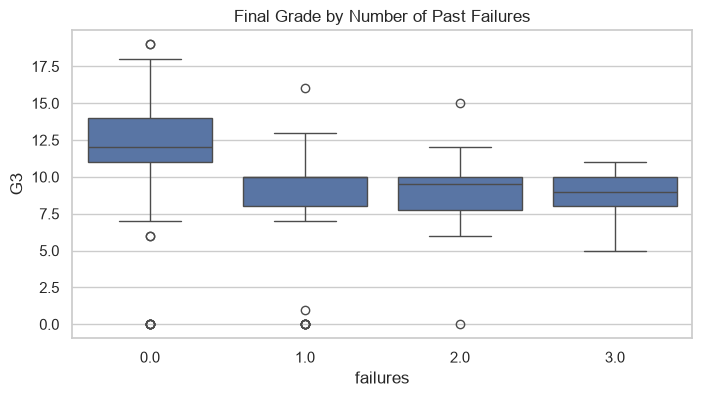

In [25]:
# Step 13
# Missing failures are treated as 0 here (structural zero; see Chapter 4)
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["failures"].fillna(0), y=df["G3"])
plt.title("Final Grade by Number of Past Failures")
plt.xlabel("failures")
plt.show()

**Step 14** – Compare the final grade between students who do and don't want to pursue higher education.

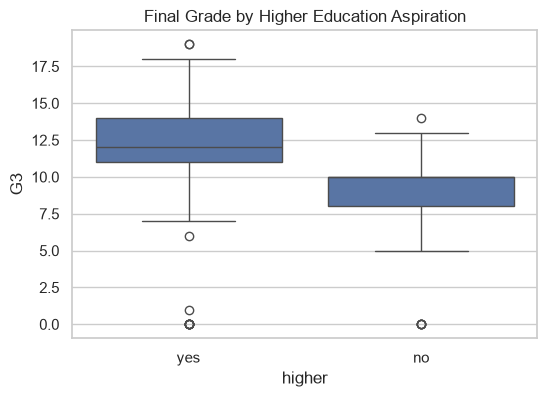

In [26]:
# Step 14
plt.figure(figsize=(6, 4))
sns.boxplot(x="higher", y="G3", data=df)
plt.title("Final Grade by Higher Education Aspiration")
plt.show()

> **Observation:** 85% of students have no recorded failure. Having at least one past failure goes with a much lower final grade (mean 12.5 for no failures vs 8.6–8.8 for 1, 2 or 3). The grade does not keep dropping after the first failure, so whether a student has failed may matter more than how many times. The 66 students who don't plan to go to higher education average 8.8, against 12.3 for those who do. These are associations, not causes.

## 3.4 Q3 – How do the two schools differ? <a id="ch3_4"></a>

**Step 15** – Compare the final grade between schools.

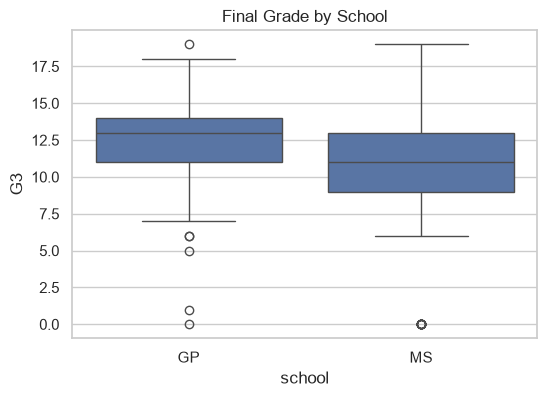

In [27]:
# Step 15
plt.figure(figsize=(6, 4))
sns.boxplot(x="school", y="G3", data=df)
plt.title("Final Grade by School")
plt.show()

**Step 16** – Compare the mean of key indicators between schools.

In [28]:
# Step 16
df.groupby("school")[["G3", "failures", "absences", "studytime", "traveltime"]].mean().round(2)

,G3,failures,absences,studytime,traveltime
school,,,,,
GP,12.58,1.55,6.38,261.57,15.68
MS,10.65,1.31,4.68,206.45,22.90


**Step 17** – Compare travel time by school and address.

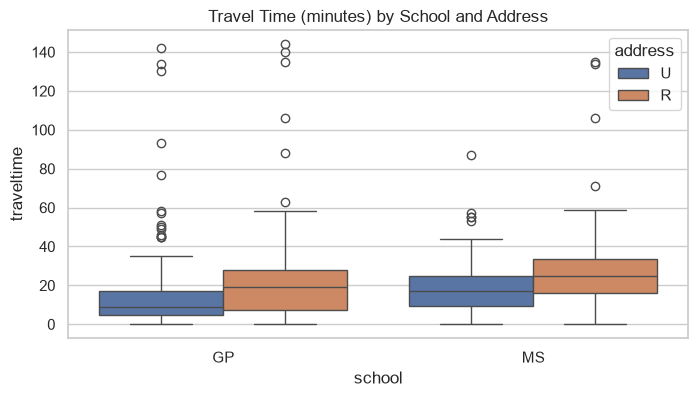

In [29]:
# Step 17
plt.figure(figsize=(8, 4))
sns.boxplot(x="school", y="traveltime", hue="address", data=df)
plt.title("Travel Time (minutes) by School and Address")
plt.show()

> **Observation:** GP students do better than MS students (mean G3 of 12.6 vs 10.7), and only 7.6% of GP students are below 10, against 30.1% at MS. MS students are also twice as likely to have a past failure (22.6% vs 11.1%), report less study time (206 vs 262 min/week) and travel longer (median 25 min for rural MS students vs 9 min for urban GP students). Because school overlaps with rural/urban context, `school` may be better used to describe clusters than to build them.

## 3.5 Q4 – What do engagement and lifestyle look like? <a id="ch3_5"></a>

**Step 18** – Plot the distribution of weekly study time.

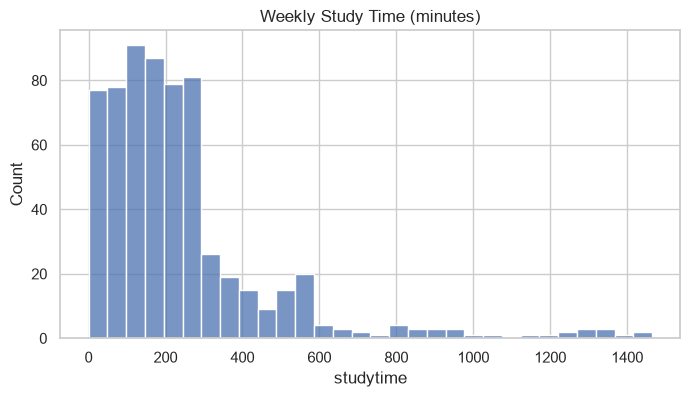

In [30]:
# Step 18
plt.figure(figsize=(8, 4))
sns.histplot(x="studytime", data=df, bins=30)
plt.title("Weekly Study Time (minutes)")
plt.show()

**Step 19** – Plot the distribution of absences.

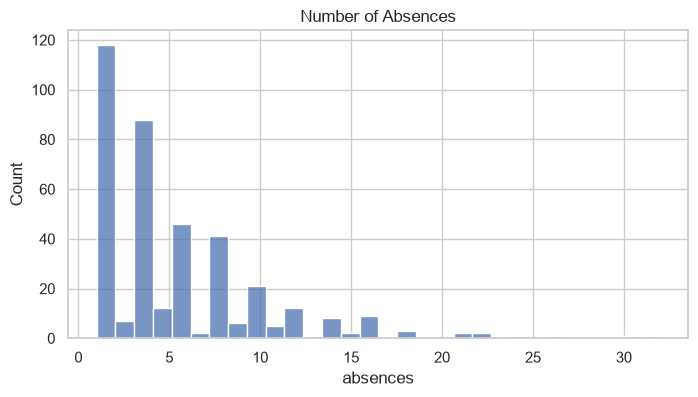

In [31]:
# Step 19
plt.figure(figsize=(8, 4))
sns.histplot(x="absences", data=df, bins=30)
plt.title("Number of Absences")
plt.show()

> **Observation:** Both variables are strongly right-skewed. `studytime` has a median of 186 min/week (about 3 hours), a skewness of 2.5, 3 students at 0 and a long tail up to 1465. `absences` (389 recorded values) has a median of 4, a skewness of 2.0 and a maximum of 32. These values are plausible, so they are kept unchanged in the data cleaning (Chapter 4), but their influence will need to be considered before any distance-based clustering.

**Step 20** – Check the relationship between absences and the final grade.

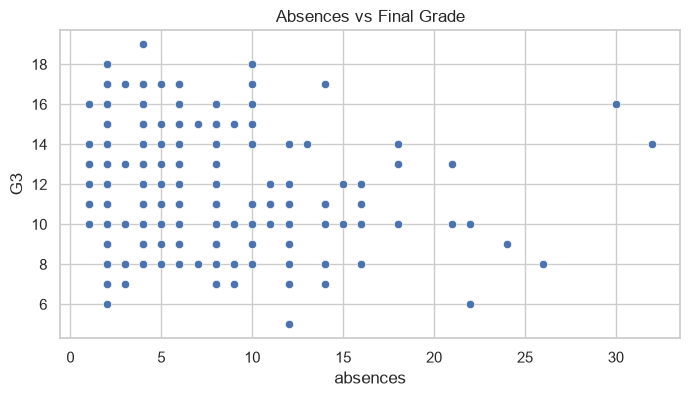

In [32]:
# Step 20
plt.figure(figsize=(8, 4))
sns.scatterplot(x="absences", y="G3", data=df)
plt.title("Absences vs Final Grade")
plt.show()

> **Observation:** The relationship between absences and the final grade is weak and negative (r = −0.15 on recorded values, −0.09 when missing values are treated as 0). Many students with high absences still pass, so absences alone do not separate students well, but they may matter in combination with other variables.

**Step 21** – Cross-tabulate workday (`Dalc`) and weekend (`Walc`) alcohol consumption.

In [33]:
# Step 21
pd.crosstab(df["Dalc"], df["Walc"])

Walc,1.0,2.0,3.0,4.0,5.0
Dalc,,,,,
1.0,222,106,57,25,5
2.0,3,30,40,32,6
3.0,1,1,8,19,12
4.0,1,1,3,4,6
5.0,1,1,0,0,14


> **Observation:** For 98% of students, weekend consumption is at least as high as workday consumption, and 67% report the minimum on workdays (Dalc = 1). The two variables are fairly strongly related (r = 0.62), so they could be combined into one alcohol indicator.

**Step 22** – Compare weekend alcohol consumption across levels of going out.

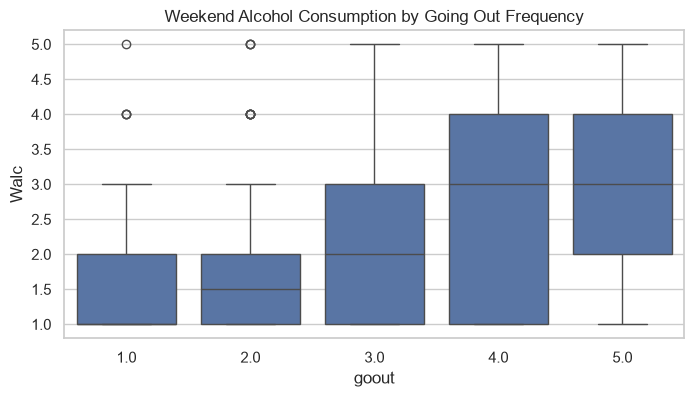

In [34]:
# Step 22
plt.figure(figsize=(8, 4))
sns.boxplot(x="goout", y="Walc", data=df)
plt.title("Weekend Alcohol Consumption by Going Out Frequency")
plt.show()

**Step 23** – Compare the final grade across weekend alcohol consumption levels.

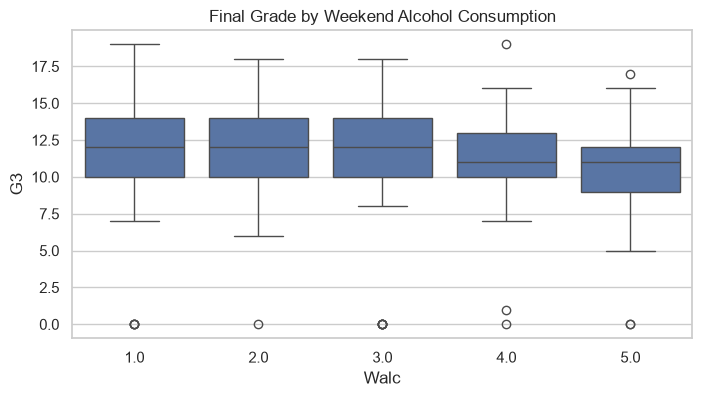

In [35]:
# Step 23
plt.figure(figsize=(8, 4))
sns.boxplot(x="Walc", y="G3", data=df)
plt.title("Final Grade by Weekend Alcohol Consumption")
plt.show()

> **Observation:** Weekend alcohol consumption increases steadily with going out (mean Walc from 1.6 at goout = 1 to 3.2 at goout = 5). The final grade drops slightly as Walc rises, from about 12.3–12.4 at levels 1–2 to 10.3 at level 5. Going out, free time and alcohol seem to form a social/lifestyle dimension.

## 3.6 Q5 – What support and family background do students have? <a id="ch3_6"></a>

**Step 24** – Check how many students receive each type of support.

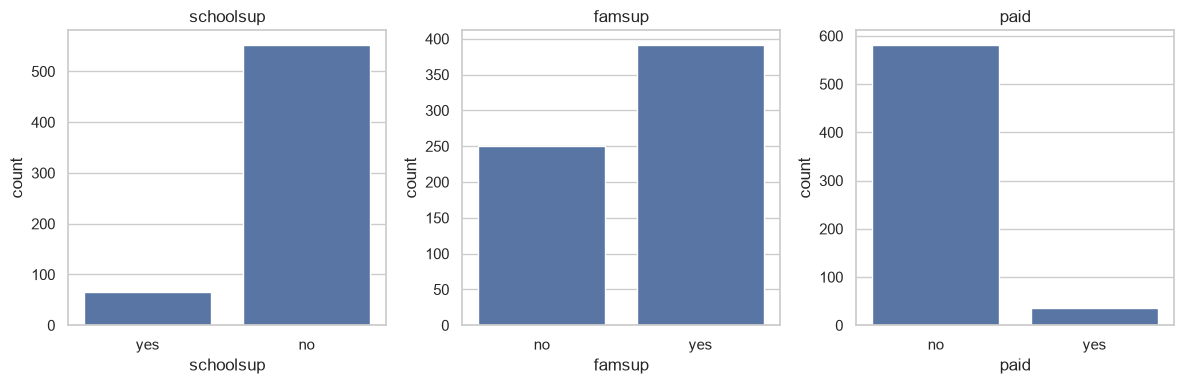

In [36]:
# Step 24
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ["schoolsup", "famsup", "paid"]):
    sns.countplot(x=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

> **Observation:** Only 36 students (5.8%) take paid classes and 66 (10.7%) receive extra school support, while 61% have family support. With 94% of students in one category, `paid` carries very little information for clustering, so it is a candidate for exclusion or for merging into a combined support indicator.

**Step 25** – Compare the final grade between students with and without extra school support.

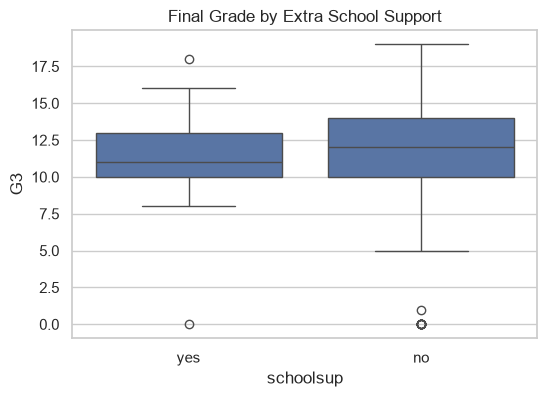

In [37]:
# Step 25
plt.figure(figsize=(6, 4))
sns.boxplot(x="schoolsup", y="G3", data=df)
plt.title("Final Grade by Extra School Support")
plt.show()

> **Observation:** Students receiving extra school support have a slightly lower final grade (mean 11.2 vs 12.0). This most likely reflects who is referred to support (students who were already struggling) rather than support lowering grades.

**Step 26** – Compare the final grade across levels of mother's education.

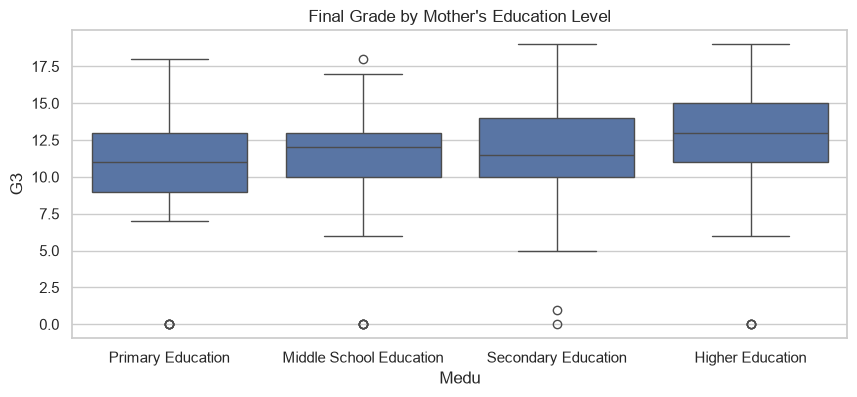

In [38]:
# Step 26
edu_order = ["Primary Education", "Middle School Education", "Secondary Education", "Higher Education"]
plt.figure(figsize=(10, 4))
sns.boxplot(x="Medu", y="G3", data=df, order=edu_order)
plt.title("Final Grade by Mother's Education Level")
plt.show()

**Step 27** – Repeat for father's education.

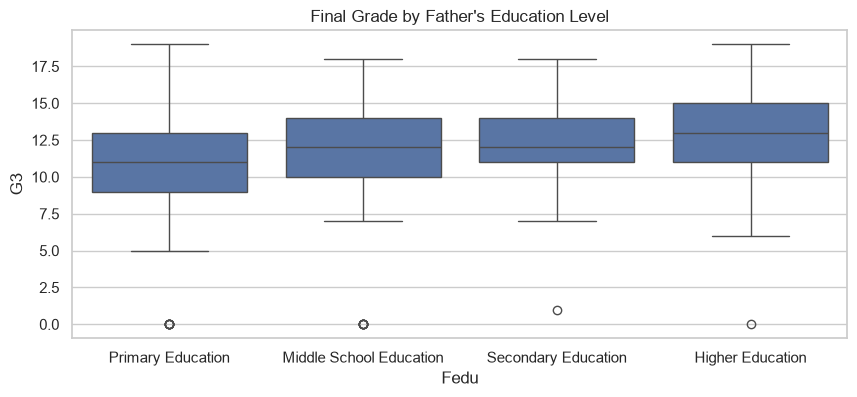

In [39]:
# Step 27
plt.figure(figsize=(10, 4))
sns.boxplot(x="Fedu", y="G3", data=df, order=edu_order)
plt.title("Final Grade by Father's Education Level")
plt.show()

> **Observation:** There is a clear gradient for both parents: the mean G3 goes from 10.8 (Primary) to 13.1 (Higher) for the mother and from 10.9 to 13.0 for the father. Since the levels have a natural order that matches the grades, `Medu` and `Fedu` behave as ordinal variables rather than unordered categories. This is why their missing values are imputed with the mode in 4.3.5, which keeps that order, rather than with a new category.

## 3.7 Correlation Analysis <a id="ch3_7"></a>

**Step 28** – Compute the Pearson correlation matrix of the numerical variables.

In [40]:
# Step 28
corr_matrix = df.select_dtypes(include="number").corr(method="pearson")

**Step 29** – Visualise the correlation matrix as a heatmap.

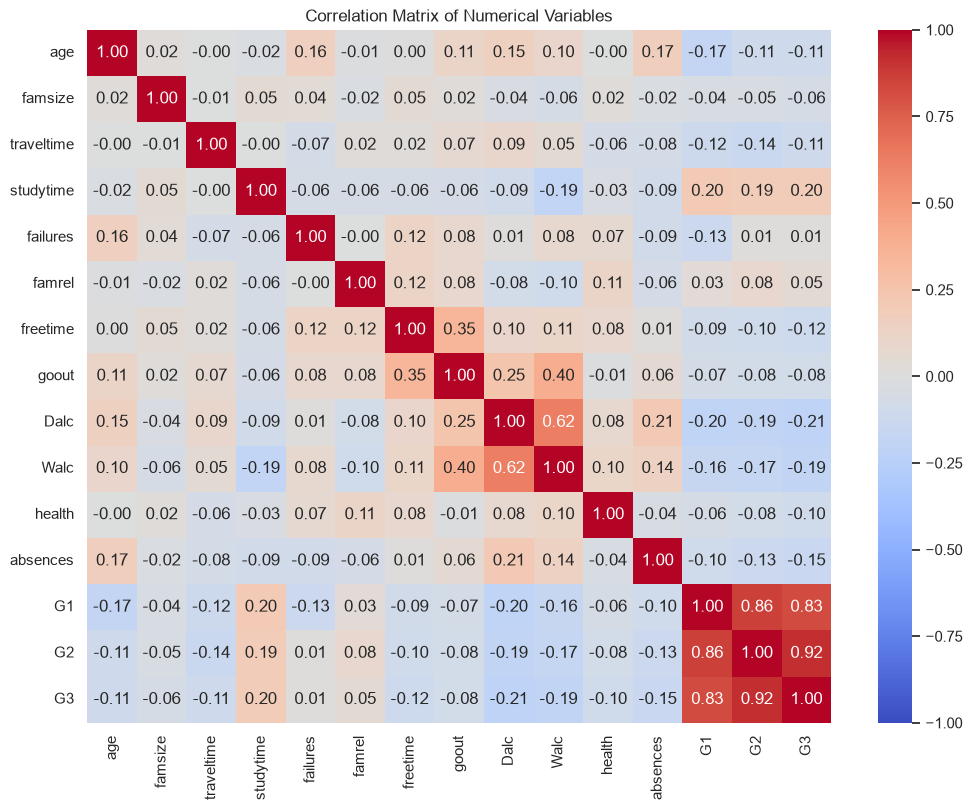

In [41]:
# Step 29
plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix of Numerical Variables")
plt.show()

> **Observation:** The three grades are very highly correlated (G2–G3 = 0.92, G1–G2 = 0.86, G1–G3 = 0.83), so using all three would count academic performance three times in the distance calculations. Other notable pairs are Dalc–Walc (0.62), goout–Walc (0.40) and freetime–goout (0.35). Apart from the grades, every variable's correlation with G3 is weak (|r| ≤ 0.21). The failures–G3 correlation of 0.01 is misleading: on the raw data it only uses the 98 students with a recorded failure. Once missing failures are treated as 0 (Step 13), the relationship is clearly negative. Correlations should be checked again after preprocessing.

## 3.8 EDA Summary & Implications for Preprocessing <a id="ch3_8"></a>

| Finding | Evidence (Step) | Decision | Where |
| :--- | :--- | :--- | :--- |
| `famsize` has impossible values (0, and 1 with parents living together) | Step 2 | Exclude `famsize` | 4.2.1 |
| 29 students have `traveltime` = 0 | Step 2 | Kept as recorded (very short commutes) | 4.2.2 |
| One student has G1 = 0 but G2 = G3 = 11 | Step 10 | Recording error: G1 replaced by G2 | 4.2.3 |
| 15 students have G3 = 0 despite non-zero G1, and all have missing absences | Steps 10–11 | Kept unchanged as a likely dropout signal | 4.2.4 |
| `failures` and `absences` never contain 0 and have many missing values | Steps 1, 2, 12 | Missing values treated as structural zeros | 4.3.1 |
| Missing parental education does not behave like the level "None" | Steps 26–27 | Imputed with the mode, keeping the order of levels | 4.3.5 |
| GP and MS differ in travel time and study time | Steps 16–17 | `traveltime` and `studytime` imputed with group medians | 4.3.6, 4.3.7 |
| `studytime`, `traveltime` and `absences` are right-skewed with extreme values | Steps 2, 18, 19 | Kept unchanged at this stage | – |
| Students aged 19–22 mostly have past failures | Step 5 | Kept as valid values | – |
| G1, G2 and G3 are highly correlated (0.83–0.92); Dalc and Walc are related (r = 0.62) | Steps 9, 21, 29 | Redundancy to keep in mind when choosing clustering variables | – |
| `paid` is 94% "no" | Steps 3, 24 | Carries little information on its own | – |
| School and address are linked, and MS students show weaker results | Steps 7, 15–17 | Context to keep in mind when comparing groups | – |


# Chapter 4: Data Preprocessing – Inconsistencies & Missing Values <a id="ch4"></a>
[Back to Table of Contents](#toc)

This chapter applies the decisions that follow from the EDA (summary table 3.8) to the inconsistencies and missing values in the data. All transformations are applied to a working copy `df_proc`, so the raw `df` is never modified. Extreme values are **kept unchanged** at this stage.

1. [Working Copy, Variable Types & Duplicates](#ch4_1)
2. [Inconsistencies](#ch4_2)
3. [Missing Values](#ch4_3)
4. [Summary of Data Cleaning](#ch4_4)


## 4.1 Working Copy, Variable Types & Duplicates <a id="ch4_1"></a>

**Step 30** – Create a working copy of the raw dataset.

In [42]:
# Step 30
df_proc = df.copy()

**Step 31** – Group the variables by type. These lists are used throughout the chapter. `famsize` is left out because it is evaluated separately in 4.2.1.

In [43]:
# Step 31
grade_cols = ["G1", "G2", "G3"]
continuous_cols = ["age", "traveltime", "studytime", "failures", "absences"]
ordinal_cols = ["famrel", "freetime", "goout", "Dalc", "Walc", "health"]
binary_cols = ["schoolsup", "famsup", "paid", "activities", "nursery", "higher", "internet", "romantic"]
education_cols = ["Medu", "Fedu"]
demographic_cols = ["school", "sex", "address", "Pstatus", "Mjob", "Fjob", "reason", "guardian"]

print(f"Numerical: {len(grade_cols + continuous_cols)} | Ordinal: {len(ordinal_cols)} | Binary: {len(binary_cols)} | "
      f"Education: {len(education_cols)} | Demographic & family: {len(demographic_cols)}")

Numerical: 8 | Ordinal: 6 | Binary: 8 | Education: 2 | Demographic & family: 8


**Step 32** – Check for duplicate student records.

In [44]:
# Step 32
n_duplicates = df_proc.duplicated().sum()
print(f"Duplicate rows: {n_duplicates}")

Duplicate rows: 0


> **Observation:** There are no duplicate records, so no rows need to be removed. The leftover index column was removed when loading the data (Chapter 2), so it cannot hide duplicates.

## 4.2 Inconsistencies <a id="ch4_2"></a>

Inconsistencies are handled **before** imputing missing values, so that imputation is based on corrected data.

### 4.2.1 Family Size: `famsize` <a id="ch4_2_1"></a>
EDA Step 2 showed that `famsize` reaches 0. We check how many records are impossible or contradictory.

**Step 33** – Count students with a family size of 0.

In [45]:
# Step 33
print(f"Students with famsize = 0: {(df_proc['famsize'] == 0).sum()}")

Students with famsize = 0: 57


**Step 34** – Count students with a family size of 1 whose parents live together (`Pstatus` = T).

In [46]:
# Step 34
print(f"Students with famsize = 1 and Pstatus = T: {((df_proc['famsize'] == 1) & (df_proc['Pstatus'] == 'T')).sum()}")

Students with famsize = 1 and Pstatus = T: 31


> **Observation:** 57 students have a family size of 0, which is impossible for an enrolled student. 31 more have a family size of 1 while living with both parents, which requires at least 3 people. In total, 88 records (13.6%) are clearly wrong, so the variable cannot be trusted for the other students either.

**Step 35** – Exclude `famsize` from the analysis.

In [47]:
# Step 35
df_proc = df_proc.drop(columns=["famsize"])

### 4.2.2 Zero Travel Times: `traveltime` <a id="ch4_2_2"></a>
EDA Step 2 showed that `traveltime` reaches 0 minutes.

**Step 36** – Show where the students with a travel time of 0 study and live.

In [48]:
# Step 36
df_proc[df_proc["traveltime"] == 0][["school", "address"]].value_counts(dropna=False).to_frame(name="Students")

Students
school address          
GP     U              24
MS     R               2
GP     R               1
       NaN             1
MS     U               1

**Step 37** – Compare the mean final grade of these students with the rest.

In [49]:
# Step 37
df_proc.groupby(df_proc["traveltime"] == 0)["G3"].mean().round(2).rename(index={False: "traveltime > 0", True: "traveltime = 0"})

traveltime
traveltime > 0    11.90
traveltime = 0    12.14
Name: G3, dtype: float64

> **Observation:** 29 students record 0 minutes, 24 of them urban GP students, the group with the shortest commutes. Their final grades are typical (12.1 vs 11.9). A value of 0 is most plausibly a very short commute rounded down (for example, living next to the school), so the values are **kept as recorded**.

### 4.2.3 Grade Recording Error: `G1` <a id="ch4_2_3"></a>
EDA Step 10 found one student with G1 = 0.

**Step 38** – Show the student with G1 = 0 but a positive G2.

In [50]:
# Step 38
df_proc[(df_proc["G1"] == 0) & (df_proc["G2"] > 0)][["G1", "G2", "G3"]]

,G1,G2,G3
0,0,11,11


> **Observation:** A grade of 0 between two grades of 11 is not plausible for the same student in the same subject, so this is a recording error.

**Step 39** – Replace that G1 with the student's G2, the closest available measure of their performance.

In [51]:
# Step 39
g1_error = (df_proc["G1"] == 0) & (df_proc["G2"] > 0)
df_proc.loc[g1_error, "G1"] = df_proc.loc[g1_error, "G2"]
print(f"G1 values corrected: {g1_error.sum()}")

G1 values corrected: 1


### 4.2.4 Final Grade of 0: `G3` <a id="ch4_2_4"></a>
EDA Steps 10–11 showed 15 students with G3 = 0 whose earlier grades were not 0. They were enrolled and assessed, so the 0 most likely reflects leaving school or missing the final exam, not a real score.

**Decision:** these students are **kept unchanged**. They are the students a school most needs to identify, so removing them would defeat the purpose of the segmentation.

## 4.3 Missing Values <a id="ch4_3"></a>

**Step 40** – Count the missing values per variable, after the corrections in 4.2.

In [52]:
# Step 40
missing = df_proc.isnull().sum().to_frame(name="Missing")
missing["Missing (%)"] = (missing["Missing"] / len(df_proc) * 100).round(2)
missing[missing["Missing"] > 0].sort_values(by="Missing", ascending=False)

,Missing,Missing (%)
failures,551,84.90
absences,260,40.06
paid,31,4.78
activities,31,4.78
goout,31,4.78
schoolsup,30,4.62
Pstatus,28,4.31
Walc,27,4.16
Medu,27,4.16
famrel,24,3.70


> **Observation:** Two variables stand out: `failures` (84.9%) and `absences` (40.1%). Every other variable is at or below 5.1% (`Medu`, 33 missing values). Each variable is treated according to its meaning in the subsections below (4.3.1–4.3.9).

### 4.3.1 Structural Zeros: `failures` & `absences` <a id="ch4_3_1"></a>
* EDA Step 2 showed that neither variable ever records a 0 (minimum = 1), even though most students have never failed and many will have perfect attendance.
* School records of this kind work *by exception*: an entry is only created when a failure or absence occurs, so a student with none has no entry, which appears as a missing value.
* **Treatment:** missing values are imputed with `0`.
* **Limitation:** the 15 students with G3 = 0 (4.2.4) all have missing absences. For them a missing value probably means "not recorded" rather than "never absent". We keep the same rule for consistency and note this caution for interpreting those students.

**Step 41** – Count the missing values in `failures` and `absences` (before imputation).

In [53]:
# Step 41
df_proc[["failures", "absences"]].isnull().sum().to_frame(name="Missing")

,Missing
failures,551
absences,260


**Step 42** – Impute missing failures with 0.

In [54]:
# Step 42
df_proc["failures"] = df_proc["failures"].fillna(0).astype(int)
df_proc["failures"].value_counts().sort_index()

failures
0    551
1     69
2     16
3     13
Name: count, dtype: int64

**Step 43** – Impute missing absences with 0.

In [55]:
# Step 43
df_proc["absences"] = df_proc["absences"].fillna(0)
print(f"Students with 0 absences: {(df_proc['absences'] == 0).sum()}")

Students with 0 absences: 260


### 4.3.2 School: `school` (1 missing value) <a id="ch4_3_2"></a>
With a single missing value, the mode (`"GP"`, 65% of students) is imputed. This has no meaningful effect on the distribution.

**Step 44** – Show the categories of `school`, with missing values (before imputation).

In [56]:
# Step 44
df_proc["school"].value_counts(dropna=False)

school
GP     422
MS     226
NaN      1
Name: count, dtype: int64

**Step 45** – Impute the missing school with the mode.

In [57]:
# Step 45
df_proc["school"] = df_proc["school"].fillna(df_proc["school"].mode()[0])
df_proc["school"].value_counts()

school
GP    423
MS    226
Name: count, dtype: int64

### 4.3.3 Sex & Address: `sex` (10) and `address` (17) <a id="ch4_3_3"></a>
Guessing a student's sex or place of residence would introduce bias, so missing values get their own category: **`"U"`** (Unidentified) for `sex` and **`"Unidentified"`** for `address`. Only 10 and 17 students are affected, so the extra category stays small while keeping these records honest.

**Step 46** – Show the categories of `sex`, with missing values (before imputation).

In [58]:
# Step 46
df_proc["sex"].value_counts(dropna=False)

sex
F      377
M      262
NaN     10
Name: count, dtype: int64

**Step 47** – Assign missing sex values to `"U"`.

In [59]:
# Step 47
df_proc["sex"] = df_proc["sex"].fillna("U")
df_proc["sex"].value_counts()

sex
F    377
M    262
U     10
Name: count, dtype: int64

**Step 48** – Show the categories of `address`, with missing values (before imputation).

In [60]:
# Step 48
df_proc["address"].value_counts(dropna=False)

address
U      443
R      189
NaN     17
Name: count, dtype: int64

**Step 49** – Assign missing address values to `"Unidentified"`.

In [61]:
# Step 49
df_proc["address"] = df_proc["address"].fillna("Unidentified")
df_proc["address"].value_counts()

address
U               443
R               189
Unidentified     17
Name: count, dtype: int64

### 4.3.4 Family & Context Variables: `Pstatus`, `Mjob`, `Fjob`, `reason`, `guardian` <a id="ch4_3_4"></a>
Missing values here may mean different things (for a parent's job: unemployed, retired, or not recorded), and the data gives no basis to choose. They are assigned to a separate **`"Unknown"`** category.

**Step 50** – Show the categories of `Pstatus`, with missing values (before imputation).

In [62]:
# Step 50
df_proc["Pstatus"].value_counts(dropna=False)

Pstatus
T      544
A       77
NaN     28
Name: count, dtype: int64

**Step 51** – Show the categories of `Mjob`, with missing values (before imputation).

In [63]:
# Step 51
df_proc["Mjob"].value_counts(dropna=False)

Mjob
other       254
at_home     135
services    135
teacher      71
health       48
NaN           6
Name: count, dtype: int64

**Step 52** – Show the categories of `Fjob`, with missing values (before imputation).

In [64]:
# Step 52
df_proc["Fjob"].value_counts(dropna=False)

Fjob
other       358
services    174
at_home      41
teacher      36
health       22
NaN          18
Name: count, dtype: int64

**Step 53** – Show the categories of `reason`, with missing values (before imputation).

In [65]:
# Step 53
df_proc["reason"].value_counts(dropna=False)

reason
course        279
home          149
reputation    142
other          72
NaN             7
Name: count, dtype: int64

**Step 54** – Show the categories of `guardian`, with missing values (before imputation).

In [66]:
# Step 54
df_proc["guardian"].value_counts(dropna=False)

guardian
mother    450
father    150
other      41
NaN         8
Name: count, dtype: int64

**Step 55** – Assign missing values in the family and context variables to `"Unknown"`, and count the new category.

In [67]:
# Step 55
for col in ["Pstatus", "Mjob", "Fjob", "reason", "guardian"]:
    df_proc[col] = df_proc[col].fillna("Unknown")

(df_proc[["Pstatus", "Mjob", "Fjob", "reason", "guardian"]] == "Unknown").sum().to_frame(name="Unknown")

,Unknown
Pstatus,28
Mjob,6
Fjob,18
reason,7
guardian,8


### 4.3.5 Parental Education: `Medu` (33) & `Fedu` (26) <a id="ch4_3_5"></a>
The project brief lists **"None"** (no formal education) as a valid level, but it never appears in the data (EDA Step 3). We test whether the missing values could be that level: if they were, these students should have the **lowest** grades, given the gradient found in EDA Steps 26–27.

**Step 56** – Show the levels of `Medu` and `Fedu`, with missing values (before imputation).

In [68]:
# Step 56
pd.DataFrame({"Medu": df_proc["Medu"].value_counts(dropna=False),
              "Fedu": df_proc["Fedu"].value_counts(dropna=False)})

,Medu,Fedu
Higher Education,167,123
Middle School Education,179,203
None,6,7
Primary Education,140,170
Secondary Education,130,127
NaN,27,19


**Step 57** – Compare the mean final grade of students with missing parental education against each level.

In [69]:
# Step 57
pd.DataFrame({
    "Medu": df_proc.groupby(df_proc["Medu"].fillna("Missing"))["G3"].mean(),
    "Fedu": df_proc.groupby(df_proc["Fedu"].fillna("Missing"))["G3"].mean()
}).round(2)

,Medu,Fedu
Higher Education,13.07,12.98
Middle School Education,11.63,11.79
Missing,12.52,12.00
None,11.67,12.14
Primary Education,10.79,10.91
Secondary Education,11.88,12.36


> **Observation:** Students with missing parental education average 12.4 (`Medu`) and 12.0 (`Fedu`), above the "Primary Education" group (10.8 and 10.9). The missing values therefore do not behave like "None". They are imputed with the mode ("Middle School Education" for both parents, which is also the median level), which keeps the natural order of the levels.

**Step 58** – Impute missing parental education with the mode.

In [70]:
# Step 58
for col in education_cols:
    df_proc[col] = df_proc[col].fillna(df_proc[col].mode()[0])

pd.DataFrame({"Medu": df_proc["Medu"].value_counts(), "Fedu": df_proc["Fedu"].value_counts()})

,Medu,Fedu
Higher Education,167,123
Middle School Education,206,222
None,6,7
Primary Education,140,170
Secondary Education,130,127


### 4.3.6 Travel Time: `traveltime` (11 missing values) <a id="ch4_3_6"></a>
Travel time depends on where the student lives and which school they attend, so each missing value is imputed with the median of students with the same **coordinates `(school, address)`**.

**Step 59** – Identify the coordinates of the students with missing travel time.

In [71]:
# Step 59
df_proc[df_proc["traveltime"].isnull()][["school", "address"]].value_counts().to_frame(name="Missing")

,,Missing
school,address,
GP,U,7
MS,R,3
GP,R,1


**Step 60** – Calculate the median travel time for each coordinate.

In [72]:
# Step 60
df_proc.groupby(["school", "address"])["traveltime"].median().to_frame(name="Median traveltime")

Median traveltime
school address                        
GP     R                          19.0
       U                           9.0
       Unidentified               15.0
MS     R                          25.0
       U                          17.0
       Unidentified               15.0

> **Observation:** Medians differ clearly by coordinate: 9 minutes for urban GP students and 25 minutes for rural MS students. A single global median (13) would understate rural commutes and overstate urban ones.

**Step 61** – Fill each missing value with the median of the student's coordinates.

In [73]:
# Step 61
# transform("median") returns, for every student, the median of their (school, address) group
coord_median = df_proc.groupby(["school", "address"])["traveltime"].transform("median")
df_proc["traveltime"] = df_proc["traveltime"].fillna(coord_median)
print(f"Missing traveltime values: {df_proc['traveltime'].isnull().sum()}")

Missing traveltime values: 0


### 4.3.7 Study Time: `studytime` (14 missing values) <a id="ch4_3_7"></a>
EDA Step 16 showed that GP students report more study time than MS students, so missing values are imputed with the **median of the student's school**, following the same logic as `traveltime`.

**Step 62** – Identify the school of the students with missing study time (before imputation).

In [74]:
# Step 62
df_proc[df_proc["studytime"].isnull()]["school"].value_counts().to_frame(name="Missing")

,Missing
school,
GP,8
MS,6


**Step 63** – Calculate the median study time for each school.

In [75]:
# Step 63
df_proc.groupby("school")["studytime"].median().to_frame(name="Median studytime")

,Median studytime
school,
GP,203.0
MS,156.0


> **Observation:** GP students' median study time is 203 min/week, against 156 for MS students. A global median would hide this difference.

**Step 64** – Fill each missing value with the median of the student's school.

In [76]:
# Step 64
school_median = df_proc.groupby("school")["studytime"].transform("median")
df_proc["studytime"] = df_proc["studytime"].fillna(school_median)
print(f"Missing studytime values: {df_proc['studytime'].isnull().sum()}")

Missing studytime values: 0


### 4.3.8 Binary Variables: `schoolsup` to `romantic` <a id="ch4_3_8"></a>
These are yes/no variables, so an `"Unknown"` level would add a third category that is neither yes nor no, and it would be very rare (1 to 31 students per variable). Each variable has at most 31 missing values (4.8%), so they are imputed with the **mode**, which changes the distributions very little.

**Step 65** – Show the categories of each binary variable, with missing values (before imputation).

In [77]:
# Step 65
df_proc[binary_cols].apply(lambda s: s.value_counts(dropna=False))

,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
no,553,250,582,320,123,66,149,409
yes,66,392,36,298,506,562,495,239
NaN,30,7,31,31,20,21,5,1


**Step 66** – Impute missing binary values with the mode of each variable.

In [78]:
# Step 66
for col in binary_cols:
    df_proc[col] = df_proc[col].fillna(df_proc[col].mode()[0])

df_proc[binary_cols].apply(lambda s: s.value_counts())

,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
no,583,250,613,351,123,66,149,410
yes,66,399,36,298,526,583,500,239


### 4.3.9 Ordinal Variables: `famrel` to `health` <a id="ch4_3_9"></a>
These 1–5 ratings have at most 31 missing values each (4.8%). They are imputed with the **median**, which is robust to skewness and always returns a valid level of the scale.

**Step 67** – Show the levels of each ordinal variable, with missing values (before imputation).

In [79]:
# Step 67
df_proc[ordinal_cols].apply(lambda s: s.value_counts(dropna=False))

,famrel,freetime,goout,Dalc,Walc,health
1.0,21,43,47,432,236,90
2.0,29,101,135,118,145,75
3.0,98,244,193,42,112,120
4.0,305,173,138,16,86,106
5.0,172,68,105,17,43,241
NaN,24,20,31,24,27,17


**Step 68** – Impute missing ordinal values with the median of each variable. The output shows the median used for each variable.

In [80]:
# Step 68
for col in ordinal_cols:
    df_proc[col] = df_proc[col].fillna(df_proc[col].median())

df_proc[ordinal_cols].median()

famrel      4.0
freetime    3.0
goout       3.0
Dalc        1.0
Walc        2.0
health      4.0
dtype: float64

**Step 69** – Check that no missing values remain.

In [81]:
# Step 69
total_missing = df_proc.isnull().sum().sum()
print(f"Remaining missing values: {total_missing} | Dataset shape: {df_proc.shape}")
assert total_missing == 0

Remaining missing values: 0 | Dataset shape: (649, 32)


## 4.4 Summary of Data Cleaning <a id="ch4_4"></a>

| Issue | Decision | Section |
| :--- | :--- | :--- |
| Duplicates | None found | 4.1 |
| `famsize` impossible values | Variable excluded | 4.2.1 |
| `traveltime` = 0 | Kept as recorded (very short commutes) | 4.2.2 |
| G1 = 0 with normal G2/G3 | Corrected to G2 | 4.2.3 |
| G3 = 0 | Kept unchanged (likely dropout) | 4.2.4 |
| `failures`, `absences` missing | Structural zeros → 0 | 4.3.1 |
| `school` (1 missing) | Mode | 4.3.2 |
| `sex`, `address` missing | Separate "U" / "Unidentified" category | 4.3.3 |
| `Pstatus`, `Mjob`, `Fjob`, `reason`, `guardian` missing | Separate "Unknown" category | 4.3.4 |
| `Medu`, `Fedu` missing | Mode (missing ≠ "None") | 4.3.5 |
| `traveltime` missing | Median by (school, address) | 4.3.6 |
| `studytime` missing | Median by school | 4.3.7 |
| Binary variables (`schoolsup`, `famsup`, `paid`, `activities`, `nursery`, `higher`, `internet`, `romantic`) missing | Mode | 4.3.8 |
| Ordinal variables (`famrel`, `freetime`, `goout`, `Dalc`, `Walc`, `health`) missing | Median | 4.3.9 |
| Extreme values in `traveltime`, `studytime`, `absences` | Kept unchanged at this stage | – |

The cleaned dataset `df_proc` has 649 students, 32 variables and no missing values (Step 69).
